# 第093讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: [build path redacted]


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "records": [
    {
      "seed": 0,
      "mode": "scratch",
      "accuracy": 0.9700000286102295,
      "encoder_max_change": 1.380875825881958,
      "target_updates": 100
    },
    {
      "seed": 0,
      "mode": "frozen",
      "accuracy": 0.9399999976158142,
      "encoder_max_change": 0.0,
      "target_updates": 100
    },
    {
      "seed": 0,
      "mode": "finetune",
      "accuracy": 0.9549999833106995,
      "encoder_max_change": 0.4568338990211487,
      "target_updates": 100
    },
    {
      "seed": 1,
      "mode": "scratch",
      "accuracy": 0.9100000262260437,
      "encoder_max_change": 1.0597344636917114,
      "target_updates": 100
    },
    {
      "seed": 1,
      "mode": "frozen",
      "accuracy": 0.9399999976158142,
      "encoder_max_change": 0.0,
      "target_updates": 100
    },
    {
      "seed": 1,
      "mode": "finetune",
      "accuracy": 0.9599999785423279,
      "encoder_max_change": 0.49598294496536255,
      "target_updates": 100
    },

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_duplicate_detector (test_experiment.TestMechanism.test_duplicate_detector) ... ok
test_frozen_encoder_unchanged (test_experiment.TestMechanism.test_frozen_encoder_unchanged) ... ok
test_independent_data (test_experiment.TestMechanism.test_independent_data) ... ok
test_iou_disjoint_identical (test_experiment.TestMechanism.test_iou_disjoint_identical) ... ok
test_iou_invalid (test_experiment.TestMechanism.test_iou_invalid) ... ok
test_iou_known (test_experiment.TestMechanism.test_iou_known) ... ok

----------------------------------------------------------------------
Ran 6 tests in 1.056s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['records', 'source_updates', 'source_train_accuracy', 'source_test_audit', 'source_target_train_audit', 'original_audit', 'injected_audit', 'metric_handcheck', 'seconds', 'environment']


01_transfer.png
02_data.png
03_mechanism.png


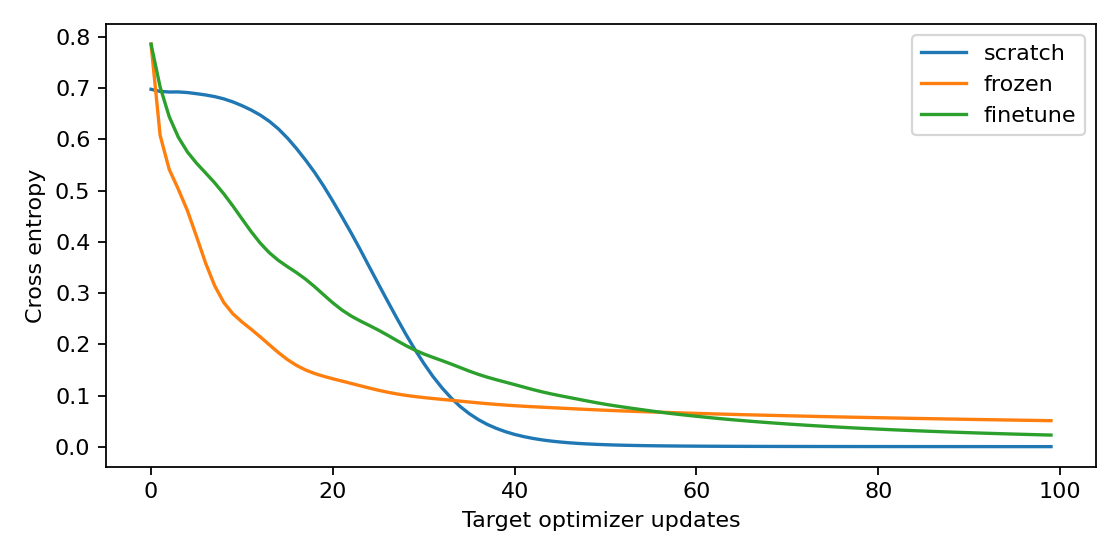

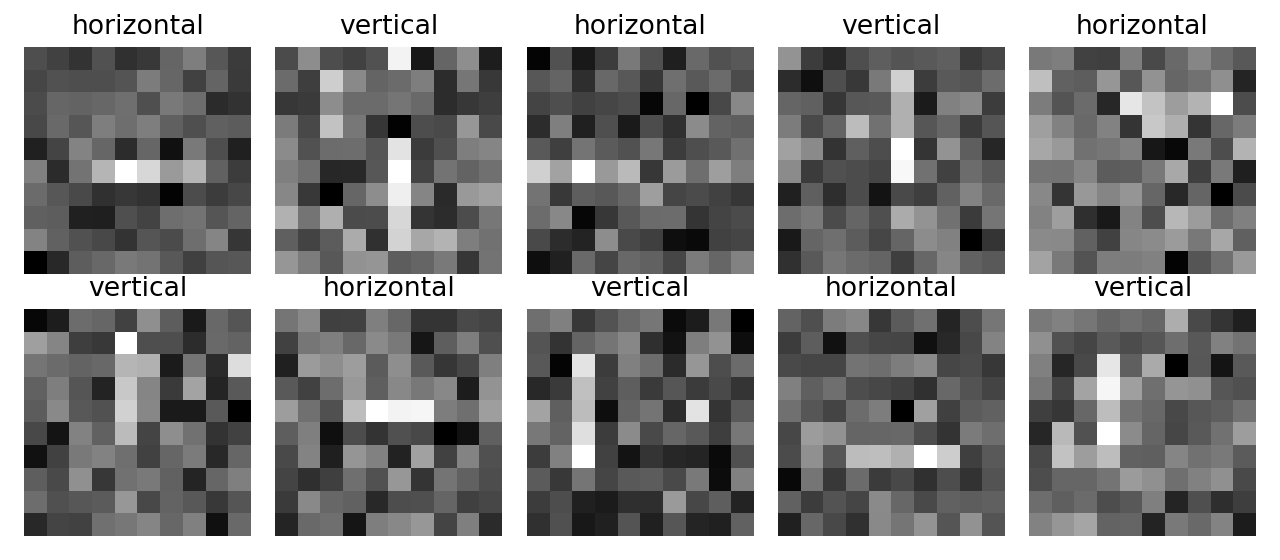

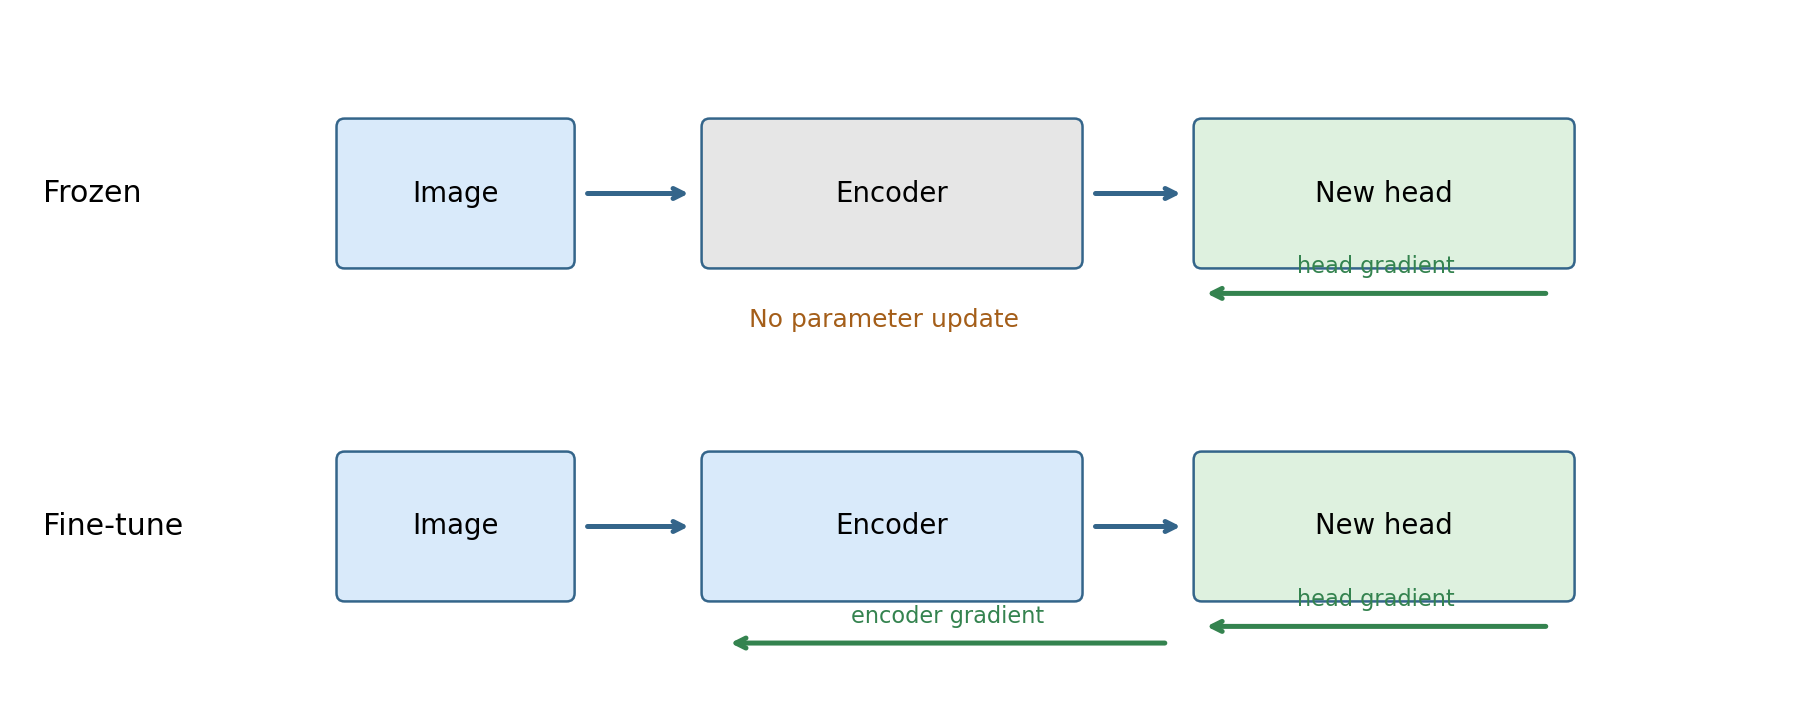

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。